# Week 03 · Student MDP — 학생 MDP: 정책 평가와 최적 가치 함수

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week03_markov_decision_process/02_student_mdp.ipynb)

슬라이드 *"Example: Student MDP"*, *"Policies (2)"*, *"Example: State-Value Function for Student MDP"*,
*"Example: Bellman Expectation Equation in Student MDP"*, *"Working Out $v_\pi$ in the Student MDP"*, *"Bellman Expectation Equation (Matrix Form)"*,
*"Example: Optimal Value Function / Optimal Action-Value Function / Optimal Policy for Student MDP"*,
*"Example: Bellman Optimality Equation in Student MDP"*, *"Working Out $v_*$ in the Student MDP"* 을 재현합니다.
랜덤 정책의 $v_\pi$를 행렬 풀이로, $v_*$와 $q_*$를 가치 반복으로 구하고 슬라이드의 숫자와 하나씩 비교합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이 노트북에서 추가로 쓰는 것
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Circle, Rectangle, FancyArrowPatch

## 1. 학생 MDP (Example: Student MDP)

MDP는 $\langle \mathcal{S}, \mathcal{A}, \mathcal{P}, \mathcal{R}, \gamma \rangle$ 입니다. 슬라이드 그림 그대로:

| 상태 | 행동 (보상) → 다음 상태 |
|---|---|
| C1 | Study ($-2$) → C2,  Youtube ($-1$) → YT |
| C2 | Study ($-2$) → C3,  Sleep ($0$) → Sleep |
| C3 | Study ($+10$) → Sleep,  Pub ($+1$) → C1 / C2 / C3 (확률 0.2 / 0.4 / 0.4) |
| YT | Youtube ($-1$) → YT,  Quit ($0$) → C1 |

Sleep은 종료 상태이고 $\gamma = 1$ 입니다. Pub은 이제 상태가 아니라 **행동**이며, 결과가 확률적인 유일한 행동입니다(그림의 검은 점).

In [2]:
STATES = ["C1", "C2", "C3", "YT", "Sleep"]
S = {s: i for i, s in enumerate(STATES)}
TERMINAL = "Sleep"

# MDP[s][a] = (reward R^a_s, {s': P^a_ss'})
MDP = {
    "C1": {"Study": (-2.0, {"C2": 1.0}), "Youtube": (-1.0, {"YT": 1.0})},
    "C2": {"Study": (-2.0, {"C3": 1.0}), "Sleep": (0.0, {"Sleep": 1.0})},
    "C3": {"Study": (10.0, {"Sleep": 1.0}), "Pub": (1.0, {"C1": 0.2, "C2": 0.4, "C3": 0.4})},
    "YT": {"Youtube": (-1.0, {"YT": 1.0}), "Quit": (0.0, {"C1": 1.0})},
}
for s in MDP:
    for a, (r, P_a) in MDP[s].items():
        assert abs(sum(P_a.values()) - 1) < 1e-12

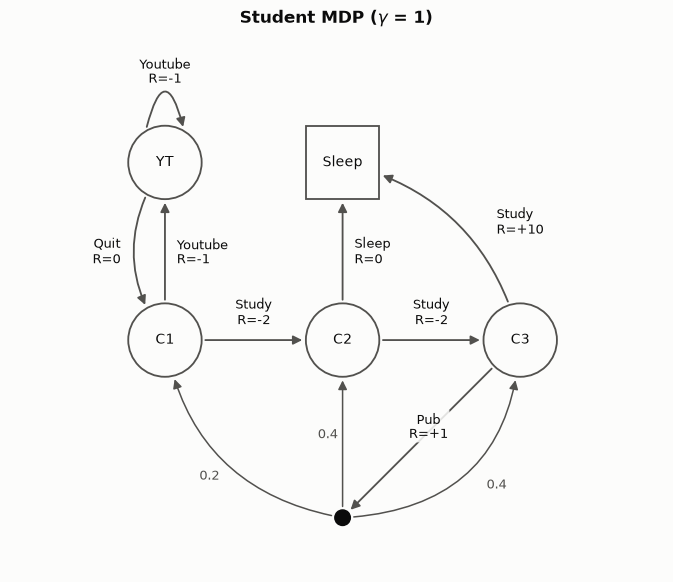

In [3]:
POS = {"C1": (0, 0), "C2": (3, 0), "C3": (6, 0), "Sleep": (3, 3), "YT": (0, 3)}
PUB_DOT = (3, -3)
NODE_R = 0.62
# 행동 화살표: (state, action) -> (curvature, label position, label alignment)
ACTION_ARROWS = {
    ("C1", "Study"): (0.0, (1.5, 0.22), "center", "bottom"),
    ("C1", "Youtube"): (0.0, (0.2, 1.5), "left", "center"),
    ("C2", "Study"): (0.0, (4.5, 0.22), "center", "bottom"),
    ("C2", "Sleep"): (0.0, (3.2, 1.5), "left", "center"),
    ("C3", "Study"): (0.3, (5.6, 2.0), "left", "center"),
    ("C3", "Pub"): (0.0, (4.45, -1.45), "center", "center"),
    ("YT", "Quit"): (0.35, (-0.75, 1.5), "right", "center"),
    ("YT", "Youtube"): (None, (0.0, 4.55), "center", "center"),
}
# Pub 이후의 확률적 전이: next state -> curvature
PUB_OUTCOMES = {"C1": -0.35, "C2": 0.0, "C3": 0.45}


def text_color_on(face_rgba):
    """Black text on light nodes, white text on dark nodes."""
    r, g, b = face_rgba[:3]
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "#0b0b0b"


def draw_mdp(ax, values=None, norm=None, q=None, q_name="q", highlight=(), title=None, value_fmt="{:.1f}"):
    """Draw the Student MDP. values: dict state->number shown in the nodes; q: dict (s, a)->number added
    to the action labels; highlight: set of (s, a) drawn in orange."""
    patches = {}
    for s, (x, y) in POS.items():
        face = mpl.colors.to_rgba("#fcfcfb") if values is None else DIV_CMAP(norm(values[s]))
        if s == TERMINAL:
            patch = Rectangle((x - NODE_R, y - NODE_R), 2 * NODE_R, 2 * NODE_R, fc=face, ec="#52514e", lw=1.2, zorder=3)
        else:
            patch = Circle((x, y), NODE_R, fc=face, ec="#52514e", lw=1.2, zorder=3)
        ax.add_patch(patch)
        patches[s] = patch
        tc = text_color_on(face)
        if values is None:
            ax.text(x, y, s, ha="center", va="center", fontsize=9, zorder=4)
        else:
            ax.text(x, y + 0.26, s, ha="center", va="center", fontsize=7.5, color=tc, zorder=4)
            ax.text(x, y - 0.13, value_fmt.format(values[s]), ha="center", va="center", fontsize=10.5,
                    fontweight="bold", color=tc, zorder=4)
    dot = Circle(PUB_DOT, 0.13, fc="#0b0b0b", ec="#0b0b0b", zorder=3)
    ax.add_patch(dot)
    patches["pub"] = dot

    def arrow(p1, p2, pA, pB, rad, color, lw):
        ax.add_patch(FancyArrowPatch(p1, p2, patchA=pA, patchB=pB, connectionstyle=f"arc3,rad={rad}",
                                     arrowstyle="-|>", mutation_scale=12, color=color, lw=lw, zorder=2))

    for (s, a), (rad, (lx, ly), ha, va) in ACTION_ARROWS.items():
        r, P_a = MDP[s][a]
        on = (s, a) in highlight
        color, lw = (PALETTE[1], 2.4) if on else ("#52514e", 1.2)
        x, y = POS[s]
        if rad is None:                                   # self-loop
            ax.add_patch(FancyArrowPatch((x - 0.32, y + 0.55), (x + 0.32, y + 0.55), connectionstyle="arc3,rad=-2.0",
                                         arrowstyle="-|>", mutation_scale=12, color=color, lw=lw, zorder=2))
        elif a == "Pub":
            arrow(POS[s], PUB_DOT, patches[s], patches["pub"], rad, color, lw)
            for s2, rad2 in PUB_OUTCOMES.items():
                arrow(PUB_DOT, POS[s2], patches["pub"], patches[s2], rad2, color, 1.6 if on else 1.0)
        else:
            s2 = next(iter(P_a))
            arrow(POS[s], POS[s2], patches[s], patches[s2], rad, color, lw)
        label = f"{a}\nR={r:+g}" if r != 0 else f"{a}\nR=0"
        if q is not None:
            label += f"\n{q_name}={q[(s, a)]:.1f}"
        ax.text(lx, ly, label, ha=ha, va=va, fontsize=8.5, linespacing=1.15, zorder=4,
                color=PALETTE[1] if on else "#0b0b0b", fontweight="bold" if on else "normal",
                bbox=dict(boxstyle="round,pad=0.12", fc="#fcfcfb", ec="none", alpha=0.85))
    for s2, (lx, ly) in {"C1": (0.75, -2.3), "C2": (2.75, -1.6), "C3": (5.6, -2.45)}.items():
        ax.text(lx, ly, f"{MDP['C3']['Pub'][1][s2]:.1f}", ha="center", va="center", fontsize=8.5, color="#52514e", zorder=4)
    ax.set_xlim(-2.6, 8.4)
    ax.set_ylim(-3.9, 5.2)
    ax.set_aspect("equal")
    ax.axis("off")
    if title:
        ax.set_title(title)


fig, ax = plt.subplots(figsize=(6.6, 5.4))
draw_mdp(ax, title="Student MDP ($\\gamma$ = 1)")
plt.tight_layout()
plt.show()

## 2. 정책이 만드는 MRP (Policies (2))

정책 $\pi$를 정하면 MDP는 MRP $\langle \mathcal{S}, \mathcal{P}^\pi, \mathcal{R}^\pi, \gamma\rangle$가 됩니다.

$$\mathcal{P}^\pi_{ss'} = \sum_a \pi(a|s)\,\mathcal{P}^a_{ss'}, \qquad \mathcal{R}^\pi_s = \sum_a \pi(a|s)\,\mathcal{R}^a_s$$

슬라이드의 정책은 각 상태에서 두 행동을 확률 $0.5$씩 고르는 균등 랜덤 정책입니다.

In [4]:
def induced_mrp(pi):
    """P^pi and R^pi (terminal state absorbing with reward 0). pi[s][a] = probability."""
    n = len(STATES)
    P_pi, R_pi = np.zeros((n, n)), np.zeros(n)
    P_pi[S[TERMINAL], S[TERMINAL]] = 1.0
    for s in MDP:
        for a, (r, P_a) in MDP[s].items():
            R_pi[S[s]] += pi[s][a] * r
            for s2, p in P_a.items():
                P_pi[S[s], S[s2]] += pi[s][a] * p
    return P_pi, R_pi


pi_random = {s: {a: 0.5 for a in MDP[s]} for s in MDP}
P_pi, R_pi = induced_mrp(pi_random)
print("P^pi   (rows: from s, columns: to s')")
print(f"{'':6}" + "".join(f"{s:>7}" for s in STATES) + f"{'R^pi':>9}")
for s in STATES:
    print(f"{s:6}" + "".join(f"{p:7.2f}" for p in P_pi[S[s]]) + f"{R_pi[S[s]]:9.2f}")
assert np.allclose(P_pi.sum(axis=1), 1)

P^pi   (rows: from s, columns: to s')
           C1     C2     C3     YT  Sleep     R^pi
C1       0.00   0.50   0.00   0.50   0.00    -1.50
C2       0.00   0.00   0.50   0.00   0.50    -1.00
C3       0.10   0.20   0.20   0.00   0.50     5.50
YT       0.50   0.00   0.00   0.50   0.00    -0.50
Sleep    0.00   0.00   0.00   0.00   1.00     0.00


예를 들어 C3에서는 Study(확률 0.5)로 Sleep에, Pub(확률 0.5)으로 C1/C2/C3에 가므로 $\mathcal{P}^\pi_{\text{C3},\cdot} = (0.1, 0.2, 0.2, 0, 0.5)$,
$\mathcal{R}^\pi_{\text{C3}} = 0.5\cdot 10 + 0.5\cdot 1 = 5.5$ 입니다.

## 3. 랜덤 정책의 가치 함수 (Example: State-Value Function for Student MDP / Bellman Expectation Equation (Matrix Form))

유도된 MRP에 대해 $v_\pi = (I - \gamma\mathcal{P}^\pi)^{-1}\mathcal{R}^\pi$ 를 풉니다. $\gamma=1$이므로 종료 상태 Sleep은 $v=0$으로 고정하고 나머지만 풉니다.

state   slide  computed
C1       -1.3   -1.3077
C2        2.7    2.6923
C3        7.4    7.3846
YT       -2.3   -2.3077
Sleep     0.0    0.0000


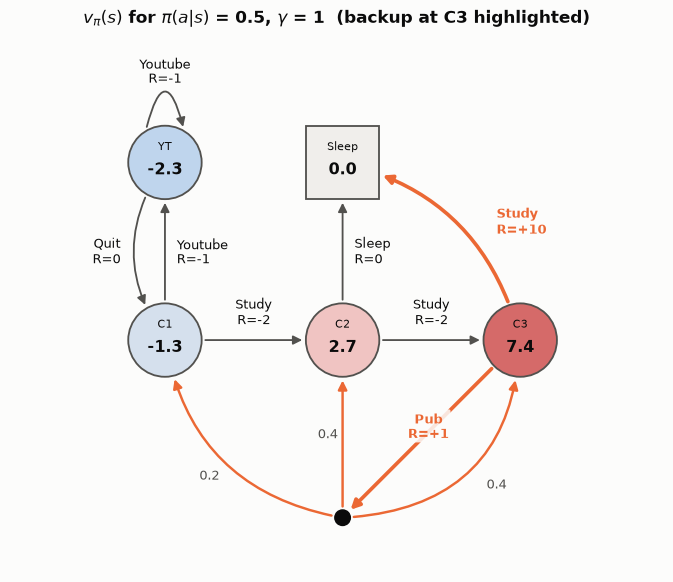

In [5]:
def evaluate_policy(pi, gamma=1.0):
    """v_pi = (I - gamma P^pi)^(-1) R^pi on the non-terminal states; v(terminal) = 0."""
    P_pi, R_pi = induced_mrp(pi)
    keep = [S[s] for s in STATES if s != TERMINAL]
    v = np.zeros(len(STATES))
    v[keep] = np.linalg.solve(np.eye(len(keep)) - gamma * P_pi[np.ix_(keep, keep)], R_pi[keep])
    return dict(zip(STATES, v))


v_pi = evaluate_policy(pi_random)
SLIDE_V_PI = {"C1": -1.3, "C2": 2.7, "C3": 7.4, "YT": -2.3, "Sleep": 0.0}
print(f"{'state':6} {'slide':>6} {'computed':>9}")
for s in STATES:
    print(f"{s:6} {SLIDE_V_PI[s]:6.1f} {v_pi[s]:9.4f}")
    assert abs(v_pi[s] - SLIDE_V_PI[s]) <= 0.05 + 1e-9

norm_pi = TwoSlopeNorm(vcenter=0, vmin=-10, vmax=10)
fig, ax = plt.subplots(figsize=(6.6, 5.4))
draw_mdp(ax, values=v_pi, norm=norm_pi, highlight={("C3", "Study"), ("C3", "Pub")},
         title="$v_\\pi(s)$ for $\\pi(a|s)$ = 0.5, $\\gamma$ = 1  (backup at C3 highlighted)")
plt.tight_layout()
plt.show()

네 값 모두 슬라이드와 일치합니다. 주황색은 슬라이드 *"Example: Bellman Expectation Equation in Student MDP"* 에서 강조된 C3의 두 행동입니다:
C3의 가치는 Study(보상 $+10$, 종료)와 Pub(보상 $+1$, 이후 C1/C2/C3로 무작위 이동)의 평균입니다.

## 4. $v_\pi$ 손으로 풀기 (Working Out $v_\pi$ in the Student MDP)

$$v_\pi(s) = \sum_a \pi(a|s)\Bigl[\mathcal{R}^a_s + \gamma\sum_{s'}\mathcal{P}^a_{ss'}\,v_\pi(s')\Bigr] = \sum_a \pi(a|s)\, q_\pi(s,a)$$

슬라이드처럼 반올림된 값($-1.3, 2.7, 7.4, -2.3$)을 오른쪽에 넣어 각 줄을 계산하고, 정확한 값과도 비교합니다.

In [6]:
def q_from_v(v, gamma=1.0):
    """q(s, a) = R^a_s + gamma * sum_s' P^a_ss' v(s')."""
    return {(s, a): r + gamma * sum(p * v[s2] for s2, p in P_a.items())
            for s in MDP for a, (r, P_a) in MDP[s].items()}


def bellman_expectation_rhs(v, pi, gamma=1.0):
    """Right-hand side sum_a pi(a|s) q(s, a) for every non-terminal state."""
    q = q_from_v(v, gamma)
    return {s: sum(pi[s][a] * q[(s, a)] for a in MDP[s]) for s in MDP}


rhs_slide = bellman_expectation_rhs(SLIDE_V_PI, pi_random)      # with the slide's rounded values
rhs_exact = bellman_expectation_rhs(v_pi, pi_random)            # with the exact values
SLIDE_LINES = {"C2": 2.7, "C1": -1.3, "YT": -2.3, "C3": 7.39}    # results printed on the slide
q_slide = q_from_v(SLIDE_V_PI)
print(f"{'state':6} {'0.5*q(a1) + 0.5*q(a2)  (slide values)':40} {'slide':>7} {'exact v_pi':>11}")
for s, result in SLIDE_LINES.items():
    a1, a2 = MDP[s]
    expr = f"0.5*({q_slide[(s, a1)]:.2f}) + 0.5*({q_slide[(s, a2)]:.2f}) = {rhs_slide[s]:.3f}"
    print(f"{s:6} {expr:40} {result:7.2f} {v_pi[s]:11.4f}")
    assert abs(rhs_slide[s] - result) < 0.005 + 1e-9         # reproduces the slide arithmetic
    assert abs(rhs_exact[s] - v_pi[s]) < 1e-12                # exact values satisfy the equation

state  0.5*q(a1) + 0.5*q(a2)  (slide values)      slide  exact v_pi
C2     0.5*(5.40) + 0.5*(0.00) = 2.700             2.70      2.6923
C1     0.5*(0.70) + 0.5*(-3.30) = -1.300          -1.30     -1.3077
YT     0.5*(-3.30) + 0.5*(-1.30) = -2.300         -2.30     -2.3077
C3     0.5*(10.00) + 0.5*(4.78) = 7.390            7.39      7.3846


슬라이드의 네 줄이 그대로 재현됩니다(C3: $5 + 2.39 = 7.39$). 정확한 값을 넣으면 등호가 완전히 성립합니다.
아래는 각 행동의 가치 $q_\pi(s,a)$입니다. $v_\pi(s)$는 두 $q_\pi$의 평균입니다.

In [7]:
q_pi = q_from_v(v_pi)
for s in MDP:
    parts = ",  ".join(f"q_pi({s},{a}) = {q_pi[(s, a)]:7.3f}" for a in MDP[s])
    print(f"{parts}   ->  v_pi({s}) = {v_pi[s]:.3f}")

q_pi(C1,Study) =   0.692,  q_pi(C1,Youtube) =  -3.308   ->  v_pi(C1) = -1.308
q_pi(C2,Study) =   5.385,  q_pi(C2,Sleep) =   0.000   ->  v_pi(C2) = 2.692
q_pi(C3,Study) =  10.000,  q_pi(C3,Pub) =   4.769   ->  v_pi(C3) = 7.385
q_pi(YT,Youtube) =  -3.308,  q_pi(YT,Quit) =  -1.308   ->  v_pi(YT) = -2.308


## 5. 최적 가치 함수 (Example: Optimal Value Function for Student MDP)

$v_*(s) = \max_\pi v_\pi(s)$ 는 벨만 최적 방정식

$$v_*(s) = \max_a \Bigl[\mathcal{R}^a_s + \gamma\sum_{s'}\mathcal{P}^a_{ss'}\,v_*(s')\Bigr]$$

의 해입니다. 이 방정식은 $\max$ 때문에 비선형이라 행렬 한 번으로 풀 수 없고(*"Solving the Bellman Optimality Equation"*),
여기서는 가치 반복(value iteration)으로 풉니다: $v_0 = 0$에서 시작해 위 식의 오른쪽을 반복 적용합니다.

In [8]:
def value_iteration(gamma=1.0, max_sweeps=1000, tol=1e-12):
    """Returns the list of value dicts v_0, v_1, ... until convergence."""
    v = {s: 0.0 for s in STATES}
    history = [v]
    for _ in range(max_sweeps):
        q = q_from_v(v, gamma)
        v_new = {s: max(q[(s, a)] for a in MDP[s]) for s in MDP}
        v_new[TERMINAL] = 0.0
        history.append(v_new)
        if max(abs(v_new[s] - v[s]) for s in STATES) < tol:
            break
        v = v_new
    return history


history = value_iteration()
print("k   " + "".join(f"{s:>8}" for s in STATES))
for k, v in enumerate(history):
    print(f"{k:<3} " + "".join(f"{v[s]:8.1f}" for s in STATES))
v_star = history[-1]

SLIDE_V_STAR = {"C1": 6, "C2": 8, "C3": 10, "YT": 6, "Sleep": 0}
assert all(abs(v_star[s] - SLIDE_V_STAR[s]) < 1e-9 for s in STATES)
print("\nv* matches the slide:", {s: v_star[s] for s in STATES})

k         C1      C2      C3      YT   Sleep
0        0.0     0.0     0.0     0.0     0.0
1       -1.0     0.0    10.0     0.0     0.0
2       -1.0     8.0    10.0    -1.0     0.0
3        6.0     8.0    10.0    -1.0     0.0
4        6.0     8.0    10.0     6.0     0.0
5        6.0     8.0    10.0     6.0     0.0

v* matches the slide: {'C1': 6.0, 'C2': 8.0, 'C3': 10.0, 'YT': 6.0, 'Sleep': 0.0}


네 번의 갱신이면 끝납니다: 보상 $+10$이 C3 → C2 → C1 → YT 순서로 한 단계씩 거꾸로 전파됩니다. 결과 $6, 8, 10, 6$은 슬라이드와 정확히 같습니다.

## 6. 최적 행동 가치 함수 (Example: Optimal Action-Value Function for Student MDP)

$$q_*(s,a) = \mathcal{R}^a_s + \gamma\sum_{s'}\mathcal{P}^a_{ss'}\, v_*(s')$$

In [9]:
q_star = q_from_v(v_star)
SLIDE_Q_STAR = {  # 슬라이드 그림의 q* 값
    ("C1", "Study"): 6, ("C1", "Youtube"): 5,
    ("C2", "Study"): 8, ("C2", "Sleep"): 0,
    ("C3", "Study"): 10, ("C3", "Pub"): 8.4,
    ("YT", "Youtube"): 5, ("YT", "Quit"): 6,
}
print(f"{'(s, a)':18} {'slide':>6} {'computed':>9}")
for sa, q_slide_val in SLIDE_Q_STAR.items():
    flag = "" if abs(q_star[sa] - q_slide_val) < 1e-9 else "   <- differs from the slide figure"
    print(f"{str(sa):18} {q_slide_val:6.1f} {q_star[sa]:9.2f}{flag}")
    if sa != ("C3", "Pub"):
        assert abs(q_star[sa] - q_slide_val) < 1e-9
# Pub: 1 + 0.2*6 + 0.4*8 + 0.4*10 = 9.4  (the slide "Working Out v_*" also uses 9.4)
assert abs(q_star[("C3", "Pub")] - 9.4) < 1e-9

(s, a)              slide  computed
('C1', 'Study')       6.0      6.00
('C1', 'Youtube')     5.0      5.00
('C2', 'Study')       8.0      8.00
('C2', 'Sleep')       0.0      0.00
('C3', 'Study')      10.0     10.00
('C3', 'Pub')         8.4      9.40   <- differs from the slide figure
('YT', 'Youtube')     5.0      5.00
('YT', 'Quit')        6.0      6.00


7개의 $q_*$가 슬라이드와 같습니다. **C3에서 Pub의 $q_*$** 는 계산하면
$1 + 0.2\cdot 6 + 0.4\cdot 8 + 0.4\cdot 10 = 9.4$ 이고, 슬라이드의 *"Working Out $v_*$"* 도 $9.4$를 씁니다.
그림(*"Example: Optimal Action-Value Function / Optimal Policy for Student MDP"*)의 $8.4$는 오기로 보입니다 — 계산값은 $9.4$입니다.
(어느 쪽이든 Study의 $10$보다 작으므로 최적 정책은 바뀌지 않습니다.)

## 7. 최적 정책 (Finding an Optimal Policy / Example: Optimal Policy for Student MDP)

$q_*$를 알면 각 상태에서 $q_*$가 가장 큰 행동을 고르는 결정적 정책이 최적입니다: $\pi_*(s) = \arg\max_a q_*(s,a)$.

optimal policy: {'C1': 'Study', 'C2': 'Study', 'C3': 'Study', 'YT': 'Quit'}
v_pi* = {'C1': 6.0, 'C2': 8.0, 'C3': 10.0, 'YT': 6.0, 'Sleep': 0.0}


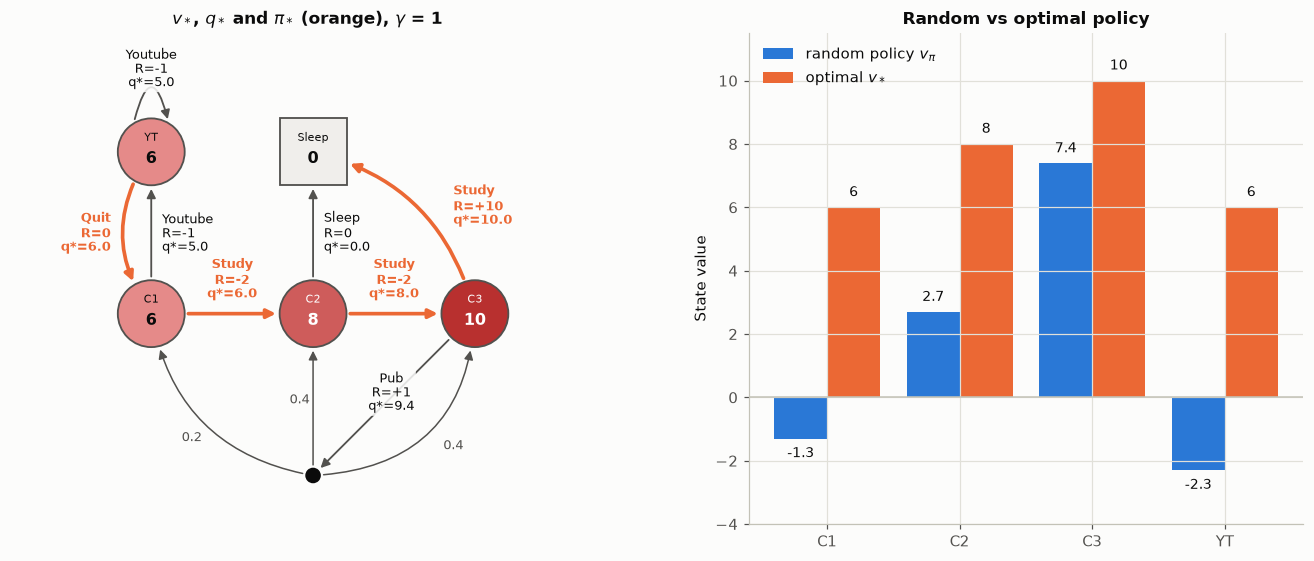

In [10]:
pi_star_actions = {s: max(MDP[s], key=lambda a: q_star[(s, a)]) for s in MDP}
print("optimal policy:", pi_star_actions)
assert pi_star_actions == {"C1": "Study", "C2": "Study", "C3": "Study", "YT": "Quit"}   # slide

# 최적 정책을 평가하면 v* 가 나와야 합니다: v_{pi*} = v*
pi_star = {s: {a: float(a == pi_star_actions[s]) for a in MDP[s]} for s in MDP}
v_pi_star = evaluate_policy(pi_star)
assert all(abs(v_pi_star[s] - v_star[s]) < 1e-9 for s in STATES)
# 최적 정책은 모든 상태에서 랜덤 정책보다 좋거나 같습니다: pi* >= pi
assert all(v_star[s] >= v_pi[s] for s in STATES)
print("v_pi* =", {s: round(float(v), 6) for s, v in v_pi_star.items()})

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.45, 1]})
norm_star = TwoSlopeNorm(vcenter=0, vmin=-10, vmax=10)
draw_mdp(axes[0], values=v_star, norm=norm_star, q=q_star, q_name="q*",
         highlight={(s, a) for s, a in pi_star_actions.items()}, title="$v_*$, $q_*$ and $\\pi_*$ (orange), $\\gamma$ = 1",
         value_fmt="{:.0f}")
ax = axes[1]
x = np.arange(4)
names = ["C1", "C2", "C3", "YT"]
ax.bar(x - 0.2, [v_pi[s] for s in names], width=0.4, color=PALETTE[0], label="random policy $v_\\pi$")
ax.bar(x + 0.2, [v_star[s] for s in names], width=0.4, color=PALETTE[1], label="optimal $v_*$")
for i, s in enumerate(names):
    ax.text(i - 0.2, v_pi[s] + (0.25 if v_pi[s] >= 0 else -0.25), f"{v_pi[s]:.1f}", ha="center",
            va="bottom" if v_pi[s] >= 0 else "top", fontsize=9)
    ax.text(i + 0.2, v_star[s] + 0.25, f"{v_star[s]:.0f}", ha="center", va="bottom", fontsize=9)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xticks(x, names)
ax.set_ylim(-4, 11.5)
ax.set_ylabel("State value")
ax.legend(loc="upper left")
ax.set_title("Random vs optimal policy")
plt.tight_layout()
plt.show()

최적 정책은 C1, C2, C3에서 Study, YT에서 Quit입니다(슬라이드와 동일). 이 정책을 평가한 $v_{\pi_*}$는 $v_*$와 같고,
모든 상태에서 랜덤 정책보다 가치가 높습니다 — 슬라이드 *"Optimal Policy"* 정리의 $\pi_* \ge \pi$ 입니다.

## 8. 벨만 최적 방정식 손으로 풀기 (Example: Bellman Optimality Equation in Student MDP / Working Out $v_*$)

이번에는 평균이 아니라 **최댓값**을 취합니다. 슬라이드의 네 줄을 그대로 계산합니다.

In [11]:
SLIDE_OPT_LINES = {  # state: (slide's numbers inside max{...}, slide's result)
    "C3": ((10, 9.4), 10),
    "C2": ((8, 0), 8),
    "C1": ((6, 5), 6),     # also the frame "Bellman Optimality Equation in Student MDP": 6 = max{-2 + 8, -1 + 6}
    "YT": ((5, 6), 6),
}
for s, (slide_terms, slide_result) in SLIDE_OPT_LINES.items():
    terms = [q_star[(s, a)] for a in MDP[s]]
    terms_txt = ", ".join(f"{a}: {t:.1f}" for a, t in zip(MDP[s], terms))
    print(f"v*({s}) = max{{{terms_txt}}} = {max(terms):.0f}   (slide: max{{{slide_terms[0]}, {slide_terms[1]}}} = {slide_result})")
    assert np.allclose(terms, slide_terms) and max(terms) == slide_result
print(f"\nat C3, Pub loses to Study by {q_star[('C3', 'Study')] - q_star[('C3', 'Pub')]:.1f}")

v*(C3) = max{Study: 10.0, Pub: 9.4} = 10   (slide: max{10, 9.4} = 10)
v*(C2) = max{Study: 8.0, Sleep: 0.0} = 8   (slide: max{8, 0} = 8)
v*(C1) = max{Study: 6.0, Youtube: 5.0} = 6   (slide: max{6, 5} = 6)
v*(YT) = max{Youtube: 5.0, Quit: 6.0} = 6   (slide: max{5, 6} = 6)

at C3, Pub loses to Study by 0.6


네 줄 모두 슬라이드와 같고, 각 줄에서 최댓값을 준 행동이 바로 7절의 최적 정책입니다. C3에서 Pub($9.4$)은 Study($10$)보다 $0.6$ 뒤집니다.

## 직접 해보기

1. $\gamma = 0.9$로 5–7절을 다시 실행해 보세요 (`value_iteration(gamma=0.9)`, `q_from_v(v, 0.9)`). $v_*$는 어떻게 바뀌고, 최적 정책은 그대로인가요?
2. $\gamma=0.9$에서 Pub의 보상을 $+1$에서 $+5$로 바꾸면 C3의 최적 행동이 Pub으로 바뀝니다. 그때 $v_*(\text{C3})$가 $10$보다 커지는 이유는 무엇일까요?
   ($\gamma = 1$에서 같은 실험을 하면 가치 반복이 수렴하지 않습니다 — 왜일까요?)
3. "성실한 학생" 정책 $\pi(\text{Study}|s) = 0.9$ (YT에서는 $\pi(\text{Quit}) = 0.9$)의 $v_\pi$를 `evaluate_policy`로 구해 랜덤 정책, $v_*$와 비교해 보세요.
4. 5절의 가치 반복 표에서 $v_k$가 $v_*$에 도달하는 순서(C3 → C2 → C1 → YT)를, 각 상태에서 C3까지의 거리와 연결해 설명해 보세요.